# Tome 0, Chapter 2: Complex Numbers and Roots of Unity (Python companion)

Exercises first, solutions at the end. The computer-science thread of this notebook is the
**discrete Fourier transform**: the roots-of-unity filter of the chapter, turned into an algorithm.

In [1]:
import cmath
from math import comb, cos, pi, prod, sin, isclose
import numpy as np
import matplotlib.pyplot as plt

## Exercises

**P2.1 (★) Draw $\mathbb U_n$.** Plot the 12th roots of unity on the unit circle, highlighting the primitive ones. How many are there? Compare with Euler's $\varphi(12)$.

In [2]:
# Your code here


**P2.2 (★) Check the chapter numerically.** Verify Exercises 2.4 (subsets of size divisible by 3, by brute force over all subsets for $n \le 15$), 2.5 (product of sines) and 2.6 ($\cos\frac{2\pi}{5}$).

In [3]:
# Your code here


**P2.3 (★★) The DFT from scratch.** Implement `dft(a)` returning $\hat a_j = \sum_k a_k\,\omega^{-jk}$ with $\omega = e^{2i\pi/n}$, and its inverse $a_k = \frac1n\sum_j \hat a_j\,\omega^{jk}$ (Proposition 2.4 is why this inverts). Compare with `numpy.fft.fft` on a random vector.

In [4]:
# Your code here


**P2.4 (★★) CS application: the FFT.** Implement the recursive Cooley–Tukey FFT for lengths that are powers of 2, using the split into even and odd indices: $\hat a_j = \hat e_j + \omega^{-j}\hat o_j$ and $\hat a_{j+n/2} = \hat e_j - \omega^{-j}\hat o_j$. Time it against your $O(n^2)$ DFT for $n = 2^{10}$.

In [5]:
# Your code here


**P2.5 (★★) CS application: multiplying polynomials and integers.** Multiply two polynomials by evaluating them at roots of unity (FFT), multiplying pointwise, and interpolating back (inverse FFT). Use it to multiply two 1000-digit integers written as digit polynomials, and check against Python's `*`.

In [6]:
# Your code here


**P2.6 (★★★) Circulants and Gauss sums.** Check $\det C = \prod_j P(\omega^j)$ (Exercise 2.7) on a random $8\times8$ circulant, and $|G|^2 = p$ (Exercise 2.8) for the first 20 odd primes. Then look at $G$ itself: what are its values? (Gauss spent years proving the answer; see Tome 1.)

In [7]:
# Your code here


---
## Solutions

### P2.1

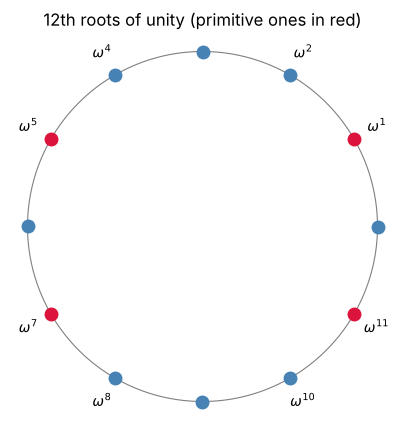

primitive exponents: [1, 5, 7, 11]  count = 4 = phi(12)


In [8]:
from math import gcd
n = 12
roots = [cmath.exp(2j * pi * k / n) for k in range(n)]
prim = [k for k in range(n) if gcd(k, n) == 1]
t = np.linspace(0, 2 * pi, 400)
plt.figure(figsize=(5, 5))
plt.plot(np.cos(t), np.sin(t), lw=0.8, color="grey")
for k, z in enumerate(roots):
    plt.plot(z.real, z.imag, "o", color="crimson" if k in prim else "steelblue", ms=9)
    plt.annotate(f"$\\omega^{{{k}}}$", (z.real * 1.15, z.imag * 1.15), ha="center", va="center")
plt.gca().set_aspect("equal"); plt.axis("off")
plt.title("12th roots of unity (primitive ones in red)")
plt.show()
print("primitive exponents:", prim, " count =", len(prim), "= phi(12)")

### P2.2

In [9]:
from itertools import combinations
for n in range(1, 16):
    brute = sum(1 for r in range(n + 1) if r % 3 == 0 for _ in combinations(range(n), r))
    assert brute == round((2**n + 2 * cos(n * pi / 3)) / 3)
for n in range(2, 40):
    assert isclose(prod(sin(k * pi / n) for k in range(1, n)), n / 2 ** (n - 1), rel_tol=1e-9)
assert isclose(cos(2 * pi / 5), (5 ** 0.5 - 1) / 4)
print("Exercises 2.4, 2.5 and 2.6 confirmed numerically.")

Exercises 2.4, 2.5 and 2.6 confirmed numerically.


### P2.3

In [10]:
def dft(a):
    n = len(a)
    w = cmath.exp(2j * pi / n)
    return [sum(a[k] * w ** (-j * k) for k in range(n)) for j in range(n)]

def idft(A):
    n = len(A)
    w = cmath.exp(2j * pi / n)
    return [sum(A[j] * w ** (j * k) for j in range(n)) / n for k in range(n)]

a = np.random.default_rng(0).normal(size=16)
assert np.allclose(dft(a), np.fft.fft(a))
assert np.allclose(idft(dft(a)), a)
print("dft agrees with numpy.fft.fft, and idft inverts it.")

dft agrees with numpy.fft.fft, and idft inverts it.


### P2.4

In [11]:
def fft(a):
    n = len(a)
    if n == 1:
        return list(a)
    even, odd = fft(a[0::2]), fft(a[1::2])
    out = [0] * n
    for j in range(n // 2):
        t = cmath.exp(-2j * pi * j / n) * odd[j]
        out[j], out[j + n // 2] = even[j] + t, even[j] - t
    return out

import time
x = list(np.random.default_rng(1).normal(size=2**10))
t0 = time.perf_counter(); slow = dft(x); t1 = time.perf_counter(); fast = fft(x); t2 = time.perf_counter()
assert np.allclose(slow, fast)
print(f"DFT O(n^2): {t1 - t0:.2f} s   FFT O(n log n): {t2 - t1:.4f} s")

DFT O(n^2): 1.20 s   FFT O(n log n): 0.0025 s


Each level of the recursion costs $O(n)$ and there are $\log_2 n$ levels, hence $O(n\log n)$ instead of $O(n^2)$. The two formulas are the roots-of-unity filter with $m = 2$: even and odd exponents separated.

### P2.5

In [12]:
def poly_mul(p, q):
    size = 1
    while size < len(p) + len(q) - 1:
        size *= 2
    P = np.fft.fft(p, size)
    Q = np.fft.fft(q, size)
    return np.rint(np.fft.ifft(P * Q).real).astype(np.int64)[: len(p) + len(q) - 1]

def int_mul(x, y):
    dx = [int(c) for c in reversed(str(x))]
    dy = [int(c) for c in reversed(str(y))]
    coeffs = poly_mul(dx, dy)
    return sum(int(c) * 10**i for i, c in enumerate(coeffs))   # carrying is done by Python here

import random
random.seed(2)
x = random.randrange(10**999, 10**1000)
y = random.randrange(10**999, 10**1000)
assert int_mul(x, y) == x * y
print("1000-digit product via FFT matches Python's exact product.")

1000-digit product via FFT matches Python's exact product.


Digit coefficients stay below $9 \cdot 9 \cdot 1000 = 81\,000$, small enough for floating-point FFT to round exactly. This is the principle behind the Schönhage–Strassen algorithm used by big-number libraries.

### P2.6

In [13]:
rng = np.random.default_rng(3)
n = 8
a = rng.normal(size=n)
C = np.array([[a[(s - r) % n] for s in range(n)] for r in range(n)])
w = np.exp(2j * np.pi / n)
assert np.isclose(np.linalg.det(C), np.prod([np.polyval(a[::-1], w**j) for j in range(n)]))
print("circulant determinant formula checked")

primes = [p for p in range(3, 80) if all(p % d for d in range(2, p))][:20]
for p in primes:
    G = sum(cmath.exp(2j * pi * a * a / p) for a in range(p))
    assert isclose(abs(G) ** 2, p, rel_tol=1e-9)
    print(f"p = {p:2d}  p mod 4 = {p % 4}  G = {G.real:+.4f} {G.imag:+.4f}i  sqrt(p) = {p ** 0.5:.4f}")

circulant determinant formula checked
p =  3  p mod 4 = 3  G = +0.0000 +1.7321i  sqrt(p) = 1.7321
p =  5  p mod 4 = 1  G = +2.2361 -0.0000i  sqrt(p) = 2.2361
p =  7  p mod 4 = 3  G = +0.0000 +2.6458i  sqrt(p) = 2.6458
p = 11  p mod 4 = 3  G = +0.0000 +3.3166i  sqrt(p) = 3.3166
p = 13  p mod 4 = 1  G = +3.6056 -0.0000i  sqrt(p) = 3.6056
p = 17  p mod 4 = 1  G = +4.1231 +0.0000i  sqrt(p) = 4.1231
p = 19  p mod 4 = 3  G = +0.0000 +4.3589i  sqrt(p) = 4.3589
p = 23  p mod 4 = 3  G = -0.0000 +4.7958i  sqrt(p) = 4.7958
p = 29  p mod 4 = 1  G = +5.3852 -0.0000i  sqrt(p) = 5.3852
p = 31  p mod 4 = 3  G = +0.0000 +5.5678i  sqrt(p) = 5.5678
p = 37  p mod 4 = 1  G = +6.0828 -0.0000i  sqrt(p) = 6.0828
p = 41  p mod 4 = 1  G = +6.4031 -0.0000i  sqrt(p) = 6.4031
p = 43  p mod 4 = 3  G = +0.0000 +6.5574i  sqrt(p) = 6.5574
p = 47  p mod 4 = 3  G = -0.0000 +6.8557i  sqrt(p) = 6.8557
p = 53  p mod 4 = 1  G = +7.2801 +0.0000i  sqrt(p) = 7.2801
p = 59  p mod 4 = 3  G = +0.0000 +7.6811i  sqrt(p) = 7.6811
p 

The pattern: $G = \sqrt p$ when $p \equiv 1 \pmod 4$ and $G = i\sqrt p$ when $p \equiv 3 \pmod 4$. Knowing $|G|$ is easy (Exercise 2.8); the sign took Gauss four years.

## Guided workshop: exact checks and certified errors
These checks exercise the new book examples. Finite calculations test the implementation; the text supplies the general proofs.

In [ ]:
import sympy as sp
roots=[sp.sqrt(3)+sp.I,-sp.sqrt(3)+sp.I,-2*sp.I]
assert all(sp.simplify(z**3-8*sp.I)==0 for z in roots)
q=1+sp.I
assert sp.expand(sum(q**k for k in range(4)))==5*sp.I
print('All three cube roots and the robot endpoint checked exactly.')
